# Clase 2 · Dengue (gemelo)

**Taller en Ciencia de Datos y Aprendizaje Automático** · Especialización en Estadística · UNAL Manizales · 2026-II
Profesor: Carlos Manuel Orrego Franco

Este cuaderno lo resuelve cada uno, de forma individual, en la segunda mitad de la clase. Es el gemelo de *El ICFES*: la misma técnica en otro mundo.

| Ficha | |
|---|---|
| **Objetivo pedagógico** | Repetir por cuenta propia el camino de la clase con un dato de vigilancia en salud: limpiar dejando cada decisión a la vista, encontrar los faltantes disfrazados, escoger la métrica según la decisión y detectar las columnas que filtran la respuesta. |
| **Enfoque** | Ciencia de Datos. |
| **Resultados de aprendizaje** | 1 (formular el problema, los objetivos y la métrica), 2 (seleccionar y preparar datos), 4 (implementar y evaluar un modelo), 5 (comunicar a quien no es técnico) y 6 (reflexión ética, técnica y operativa). |
| **Uso de IA** | Pueden pedirle a Claude que explique una celda, que les ayude a llenar un hueco o que interprete un error. Deben poder explicar sin ayuda qué significa un `-89`, por qué se descartaron unos años, cómo se dedujo el significado de los códigos, por qué `conducta` y `clasfinal` no pueden entrar al modelo y qué mide la captación. |
| **Entregable** | El cuaderno completo y corrido en su portafolio de GitHub, con las predicciones escritas, la decisión en tres frases, la bitácora y la tabla de la sección 4.5 llenas. |

**Cómo se trabaja.** El código está escrito casi todo. Donde vean `____` falta una pieza, y el comentario de al lado dice qué va. Lean la celda entera antes de llenar. Si una celda falla, lean el error antes de pedir ayuda.

In [1]:
# Celda de arranque. No hay que cambiarle nada: trae las herramientas del curso.
import pathlib, subprocess, sys
raiz = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.cwd() / "taller-cd-ml-2026-2"] if (p / "taller" / "datos.py").exists()), None)
if raiz is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/cmorregof/taller-cd-ml-2026-2.git"], check=True)
    raiz = pathlib.Path("taller-cd-ml-2026-2")
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from taller import descargar, procedencia

PALETA = ["#1D4E89", "#D7263D", "#1B998B", "#6C4AB6", "#5BC0EB", "#F49097", "#9AA5B1"]      # colores del curso
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETA), "axes.titleweight": "bold", "figure.dpi": 110})
print("Herramientas listas.")

Herramientas listas.


## 1. Formulación

Cada vez que un médico en Colombia atiende un caso de dengue llena una ficha de notificación para el sistema de vigilancia, SIVIGILA. La ficha registra quién es el paciente, qué síntomas tiene, si quedó hospitalizado y cómo se clasificó el caso. Las alcaldías de Bucaramanga y de Tuluá publican esas fichas, sin nombres, en datos.gov.co.

Imagínense el equipo de vigilancia de la Secretaría de Salud de Bucaramanga en plena epidemia. Llegan cientos de fichas por semana y el equipo alcanza a hacerle seguimiento telefónico a tres de cada diez casos. Necesita tres respuestas:

1. **Predecir.** Con lo que dice la ficha sobre el paciente y sus síntomas, ¿qué casos terminan hospitalizados?
2. **Explicar.** ¿Qué síntomas y qué condiciones del paciente acompañan la hospitalización?
3. **Decidir.** Si el equipo solo puede seguir al 30 % de los casos, ¿a cuáles llama, y a quiénes deja sin llamada esa regla?

**La respuesta que vamos a modelar.** $y_i=1$ si la ficha dice que el paciente $i$ fue hospitalizado, y $y_i=0$ si no.

**La métrica** es la misma de la clase. El modelo ordena los casos por riesgo, el equipo llama a los primeros $k$ y medimos la **captación**:

$$\text{captación}=\frac{\#\{i:\ y_i=1\ \text{y}\ i\ \text{recibe llamada}\}}{\#\{i:\ y_i=1\}}.$$

### Predicción escrita

Escriban su apuesta antes de correr nada.

- De cada cien casos de dengue notificados, ¿cuántos terminan hospitalizados? **Mi apuesta:**
- ¿Qué síntoma separa mejor a los hospitalizados de los demás? **Mi apuesta:**
- El protocolo médico ya dice que un paciente con signos de alarma se hospitaliza. ¿Un modelo le ganará a esa regla? **Mi apuesta:**

- 30 casos, osea alrededor del 30%
- Dolor abdominal y sangrado en las encias
- No

## 2. Datos

La primera celda fija los parámetros del cuaderno. La segunda trae las fichas y tarda unos veinte segundos.

In [2]:
CIUDAD = "bucaramanga"       # al final lo cambiarán por "tulua"
CUPO = 0.30                  # fracción de casos a la que el equipo alcanza a llamar
DESDE = 2021                 # primer año que entra al análisis. La sección 2.4 explica por qué

In [3]:
crudo = descargar("dengue", ciudad=CIUDAD)
print("Filas:", len(crudo), "| Columnas:", crudo.shape[1])
from taller.presentacion import ficha_del_dato, RegistroDeLimpieza, resumen_pca, nube_3d, CIELO, ROJO
display(ficha_del_dato(crudo, f"Fichas de dengue, {CIUDAD.title()}", maximo=80))
crudo.head(3).T

[dengue] Descargo de la fuente oficial: Alcaldías de Bucaramanga y de Tuluá, en datos.gov.co, conjuntos qzc7-jbg3 y dq2k-gub9.
[dengue] Listo: 28.626 filas.


/content/taller-cd-ml-2026-2/taller/datos.py:179: DtypeWarning: Columns (59,60) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(en_cache)


Filas: 28626 | Columnas: 61


,tipo,sin dato (%),valores distintos,ejemplo
columna,,,,
cod_eve,int64,0.0,3,210
fec_not,object,0.0,3364,2015-04-01T00:00:00.000
semana,int64,0.0,53,1
a_o,int64,0.0,11,2015
grupo_etario,object,0.0,22,10 A 14
clasif_edad,object,0.0,12,7 A 11
def_clas_edad,object,0.0,12,INFANCIA
sexo_,object,0.0,2,M
tip_ss_,object,0.0,12,CONTRIBUTIVO


,0,1,2
columna,,,
cod_eve,210,210,210
fec_not,2015-04-01T00:00:00.000,2015-05-01T00:00:00.000,2015-05-01T00:00:00.000
semana,1,1,1
a_o,2015,2015,2015
grupo_etario,10 A 14,15 A 19,20 A 29
...,...,...,...
hemorr_hem,2,2,2
choque,2,2,2
da_o_organ,2,2,2


### 2.1 Primera trampa: números y letras en la misma columna

Si están con Bucaramanga, la descarga soltó un aviso en rojo, `DtypeWarning`, que dice que dos columnas mezclan tipos. Ese aviso es una pista. Miren qué hay en tres columnas.

In [4]:
for columna in ["clasfinal", "conducta", "tip_ss_"]:
    print(crudo[columna].astype(str).value_counts().to_string(), "\n")

clasfinal
1                                      11702
2                                       6615
DENGUE-89CON-89SIGNOS-89DE-89ALARMA     6102
DENGUE-89SIN-89SIGNOS-89DE-89ALARMA     4031
3                                        136
DENGUE-89GRAVE                            26
0                                         12
-89                                        2 

conducta
1                                11188
HOSPITALIZACION PISO              5462
2                                 5460
AMBULATORIA                       4117
5                                  835
4                                  491
3                                  480
OBSERVACION                        441
REMISION PARA HOSPITALIZACION       97
UNIDAD DE CUIDADOS INTENSIVOS       40
0                                   12
NO APLICA                            2
-89                                  1 

tip_ss_
C                12549
CONTRIBUTIVO      6926
S                 4933
SUBSIDIADO        2469
P         

En Bucaramanga conviven dos maneras de escribir lo mismo. Unas fichas dicen `1`, `2`, `3` y otras dicen el nombre completo. Además el nombre viene dañado: donde debería haber un espacio dice `-89`, y por eso se lee `DENGUE-89CON-89SIGNOS-89DE-89ALARMA`. Alguien reemplazó todos los espacios vacíos de la tabla por `-89` y se llevó por delante los espacios entre palabras. En Tuluá todo viene en códigos, pero el mismo código aparece como `2` y como `2.0`.

Las tres funciones de la celda siguiente son las herramientas de limpieza de todo el cuaderno. `texto` deja una columna en mayúsculas y sin el `-89`. `codigo` la convierte en número, y lo que no sea número queda como faltante. `fecha` se explica en la sección 2.3.

In [5]:
def texto(columna):
    return crudo[columna].astype(str).str.replace("-89", " ").str.strip().str.upper()

def codigo(columna):
    return pd.to_numeric(crudo[columna], errors="coerce")

print(texto("clasfinal").value_counts().head(8).to_string())

clasfinal
1                              11702
2                               6615
DENGUE CON SIGNOS DE ALARMA     6102
DENGUE SIN SIGNOS DE ALARMA     4031
3                                136
DENGUE GRAVE                      26
0                                 12
                                   2


### 2.2 Segunda trampa: faltantes disfrazados

Un faltante honesto es una celda vacía. Un faltante disfrazado es un valor que parece un dato. Esta tabla tiene de los dos, y el disfraz más usado es el `-89`.

In [6]:
disfrazados = crudo.apply(lambda columna: (pd.to_numeric(columna, errors="coerce") == -89).sum())
vacios = crudo.isna().sum()
resumen_faltantes = pd.DataFrame({"-89": disfrazados, "vacíos": vacios})
print(resumen_faltantes[(resumen_faltantes.sum(axis=1) > 0)].sort_values("-89", ascending=False).head(12).to_string())
print("\nEstrato, tal como viene:")
print(crudo["estrato_"].astype(str).value_counts().to_string())

              -89  vacíos
columna                  
sem_ges_    28522       0
fuente_      6221       0
estrato_     5864     615
famantdngu   4727       0
cod_pais_r   4440       0
da_o_organ    139       0
hemorr_hem    139       0
choque        139       0
extravasac    138       0
gp_gestan      34       0
gp_mad_com     24       0
desplazami      9       0

Estrato, tal como viene:
estrato_
3.0      7960
2.0      7827
-89.0    5864
1.0      3023
4.0      2802
nan       615
5.0       352
6.0       183


Si alguien promedia el estrato sin mirar, cada `-89` entra a la cuenta como un estrato negativo. El promedio sale absurdo y nadie avisa. **Decisión:** todo `-89` se convierte en faltante.

In [8]:
estrato = codigo("estrato_").replace(-89, np.nan)          # HUECO 1: el número que disfraza los faltantes
print("Estrato promedio sin limpiar:", round(codigo("estrato_").mean(), 2), "| limpio:", round(estrato.mean(), 2))
print("Fichas sin estrato:", int(estrato.isna().sum()))

Estrato promedio sin limpiar: -16.61 | limpio: 2.56
Fichas sin estrato: 6479


### 2.3 Tercera trampa: fechas en dos formatos y fechas de 1900

La ficha tiene tres fechas que nos interesan: inicio de síntomas (`ini_sin_`), consulta (`fec_con_`) y notificación (`fec_not`).

In [9]:
for columna in ["fec_not", "ini_sin_", "fec_con_"]:
    valores = crudo[columna].astype(str)
    print(f"{columna:9s} con barras: {valores.str.contains('/').sum():4d} | de 1900: {valores.str.startswith('1900').sum():4d} | ejemplos: {valores.iloc[0]}  {valores[valores.str.contains('/')].head(1).tolist()}")

fec_not   con barras:  116 | de 1900:    0 | ejemplos: 2015-04-01T00:00:00.000  ['27/12/2023']
ini_sin_  con barras:  116 | de 1900:    0 | ejemplos: 2015-01-04T00:00:00.000  ['20/12/2023']
fec_con_  con barras:  116 | de 1900:    0 | ejemplos: 2015-01-04T00:00:00.000  ['24/12/2023']


Casi todas las fechas vienen como `2024-06-24T00:00:00.000`. En Bucaramanga, unas pocas vienen como `24/06/2024`. Si se le pide a pandas que adivine, puede leer `02/01/2024` como el 1 de febrero. Por eso la función `fecha` prueba los dos formatos de manera explícita. También convierte en faltante cualquier fecha de 1900, que es otro disfraz.

In [12]:
def fecha(columna):
    valores = crudo[columna].astype(str)
    iso = pd.to_datetime(valores.str[:10], format="%Y-%m-%d", errors="coerce")
    con_barras = pd.to_datetime(valores, format="%d/%m/%Y", errors="coerce")     # HUECO 2: el formato día/mes/año con barras, entre comillas
    resultado = iso.fillna(con_barras)
    return resultado.where(resultado.dt.year > 1900)

notificacion, sintomas, consulta = fecha("fec_not"), fecha("ini_sin_"), fecha("fec_con_")
print("Fechas de notificación sin leer:", int(notificacion.isna().sum()))
print("Notificaciones entre", notificacion.min().date(), "y", notificacion.max().date())

Fechas de notificación sin leer: 0
Notificaciones entre 2015-01-02 y 2025-09-02


**Compruébenlo ustedes mismos.** Deben quedar cero fechas de notificación sin leer. Si no, revisen el hueco 2.

### 2.4 Cuarta trampa: años en que nadie llenó los síntomas

El dengue se define como una enfermedad con fiebre. Una ficha de dengue sin fiebre es rara, y un año entero sin fiebre no puede ser. Miren, año por año, qué fracción de las fichas marca fiebre, cuántas no tienen estrato y cuántas dicen hospitalizado. En las columnas de síntomas, el `1` es «sí» y el `2` es «no».

In [14]:
anio = notificacion.dt.year
por_anio = pd.DataFrame({
    "fichas": anio.value_counts().sort_index(),
    "% con fiebre": ((codigo("fiebre") == 1).groupby(anio).mean() * 100).round(1),
    "% sin estrato": (estrato.isna().groupby(anio).mean() * 100).round(1),
    "% hospitalizado": ((codigo("pac_hos_") == 1).groupby(anio).mean() * 100).round(1),      # HUECO 3: el código que significa "sí"
})
por_anio.index = por_anio.index.astype(int)
display(por_anio)

,fichas,% con fiebre,% sin estrato,% hospitalizado
fec_not,,,,
2015,2655,100.0,100.0,11.6
2016,2268,99.8,100.0,13.0
2017,418,0.2,100.0,19.9
2018,641,0.8,18.6,32.6
2019,2803,0.7,8.8,40.9
2020,891,1.6,13.4,42.1
2021,294,99.0,12.9,52.4
2022,926,99.9,0.4,60.2
2023,3681,100.0,1.7,41.3


En Bucaramanga hay años en que casi ninguna ficha marca fiebre. Esos años las columnas de síntomas dicen «no» en todo, y ese «no» es otro faltante disfrazado: el síntoma no se capturó. Un modelo entrenado con esos años aprendería que hay hospitalizados sin un solo síntoma. Los primeros años tampoco traen estrato.

**Decisión:** el análisis usa las fichas desde `DESDE = 2021`, que es el primer año de Bucaramanga con síntomas y estrato. Para Tuluá, que empieza en 2023, la regla no quita nada. Anótenla en la bitácora.

### 2.5 Quinta trampa: códigos sin diccionario

Las alcaldías publican la tabla sin diccionario. La ficha de datos básicos del INS, que es pública, documenta algunos códigos: en `tip_cas_`, 2 es probable, 3 es confirmado por laboratorio y 5 es confirmado por nexo epidemiológico; en `ajuste_`, **6 es caso descartado**; en `con_fin_`, 1 es vivo y 2 es muerto.

Para `conducta` y `clasfinal` no conseguí el diccionario oficial al preparar la clase, porque el sitio del INS no respondió. Lo que sí hay es evidencia dentro del dato. Bucaramanga trae los dos sistemas, códigos y nombres, y se puede ver qué código se comporta como qué nombre.

In [15]:
reciente = (anio >= DESDE).values
hospitalizado = codigo("pac_hos_") == 1
grave = codigo("cod_eve") == 220                       # 210 es dengue, 220 es dengue grave, 580 es mortalidad por dengue
for columna in ["conducta", "clasfinal"]:
    valor = texto(columna).str.replace(r"\.0$", "", regex=True)[reciente]
    evidencia = pd.DataFrame({"fichas": valor.value_counts(),
                              "% hospitalizado": (hospitalizado[reciente].groupby(valor).mean() * 100).round(1),
                              "% notificado como dengue grave": (grave[reciente].groupby(valor).mean() * 100).round(1)})
    print(columna); print(evidencia[evidencia["fichas"] >= 20].sort_index().to_string(), "\n")

conducta
                               fichas  % hospitalizado  % notificado como dengue grave
conducta                                                                              
1                               11188              0.7                             0.0
2                                5460             98.2                             0.1
3                                 480             98.1                            25.4
4                                 491             62.5                             0.0
5                                 835             16.0                             1.0
AMBULATORIA                       198              4.0                             0.0
HOSPITALIZACION PISO              206             96.1                             0.5
OBSERVACION                        45             75.6                             0.0
REMISION PARA HOSPITALIZACION      27             14.8                             0.0 

clasfinal
                      

Con Bucaramanga la tabla permite emparejar. En `conducta`, el código 1 casi nunca coincide con hospitalización, igual que `AMBULATORIA`. El 2 coincide casi siempre, igual que `HOSPITALIZACION PISO`. El 3 coincide casi siempre y concentra los casos graves, igual que `UNIDAD DE CUIDADOS INTENSIVOS`. El 4 y el 5 se parecen a `OBSERVACION` y a `REMISION PARA HOSPITALIZACION`. En `clasfinal`, el 3 es el único código que coincide con la notificación de dengue grave, y el 1 y el 2 se comportan como «sin signos de alarma» y «con signos de alarma».

| Columna | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| `conducta` | Ambulatoria | Hospitalización en piso | Cuidados intensivos | Observación | Remisión para hospitalización |
| `clasfinal` | Sin signos de alarma | Con signos de alarma | Dengue grave | | |

Este diccionario es una **deducción**, y la evidencia es de comportamiento: los códigos y los nombres están en fichas distintas, así que no hay una sola fila que traiga los dos. Para Tuluá supongo que rige la misma ficha nacional. Antes de usar esto fuera de clase habría que confirmarlo con el INS.

**Sexta trampa: fichas que no son casos.** Una ficha con `ajuste_` igual a 6 es un caso que se descartó: se sospechó dengue y resultó otra cosa. Las fichas con `cod_eve` 580 son registros de mortalidad.

In [16]:
print("Valores de ajuste_:"); print(codigo("ajuste_")[reciente].value_counts().sort_index().to_string())
print("\nFichas de mortalidad (cod_eve 580):", int((codigo("cod_eve")[reciente] == 580).sum()))

Valores de ajuste_:
ajuste_
0    10864
3     5199
5       51
7     2836

Fichas de mortalidad (cod_eve 580): 12


**Decisión:** las fichas descartadas salen, porque esos pacientes no tuvieron dengue. Las de mortalidad también salen, porque registran otro evento. Comparen cuántas fichas descartadas hay en cada ciudad cuando lleguen a la sección 4.5.

### 2.6 La tabla limpia

Esta celda reúne todas las decisiones. La edad viene en grupos con nombres distintos en cada ciudad, y por eso hay un pequeño diccionario que lleva las dos a la misma escala de curso de vida.

In [18]:
COLUMNA_EDAD = {"bucaramanga": "def_clas_edad", "tulua": "clas_edad"}
CURSO_DE_VIDA = {"PRIMERA INFANCIA": 0, "INFANCIA": 1, "ADOLESCENCIA": 2, "ADOLECENCIA": 2, "JOVENES": 3, "JUVENTUD": 3,
                 "ADULTEZ": 4, "ADULTES": 4, "VEJEZ": 5, "PERSONA MAYOR": 5}
SINTOMAS = ["fiebre", "cefalea", "dolrretroo", "malgias", "artralgia", "erupcionr"]
ALARMA = ["dolor_abdo", "vomito", "diarrea", "somnolenci", "hipotensio", "hepatomeg", "hem_mucosa", "hipotermia", "aum_hemato", "caida_plaq", "acum_liqui"]
CONDUCTA = {"AMBULATORIA": 1, "HOSPITALIZACION PISO": 2, "UNIDAD DE CUIDADOS INTENSIVOS": 3, "OBSERVACION": 4, "REMISION PARA HOSPITALIZACION": 5}
CLASIFICACION = {"DENGUE SIN SIGNOS DE ALARMA": 1, "DENGUE CON SIGNOS DE ALARMA": 2, "DENGUE GRAVE": 3}

limpio = pd.DataFrame(index=crudo.index)
limpio["fecha"] = notificacion
limpio["hospitalizado"] = (codigo("pac_hos_") == 1).astype(int)
limpio["mujer"] = (texto("sexo_") == "F").astype(float)
limpio["curso_de_vida"] = texto(COLUMNA_EDAD[CIUDAD]).map(CURSO_DE_VIDA)
limpio["estrato"] = estrato.where(estrato.between(1, 6))
limpio["subsidiado"] = (texto("tip_ss_").str[0] == "S").astype(float)       # la primera letra sirve para los dos sistemas: S y SUBSIDIADO
limpio["dias_hasta_consulta"] = (consulta - sintomas).dt.days            # HUECO 4: la fecha que se resta para saber cuánto esperó el paciente
for columna in SINTOMAS + ALARMA:
    limpio[columna] = (codigo(columna) == 1).astype(float)
limpio["signos_de_alarma"] = limpio[ALARMA].sum(axis=1)                     # cuántos signos de alarma marca cada ficha

# Dos columnas que NO entran al modelo. Se guardan para la sección 3.5.
limpio["conducta"] = codigo("conducta").fillna(texto("conducta").map(CONDUCTA))
limpio["clasfinal"] = codigo("clasfinal").fillna(texto("clasfinal").map(CLASIFICACION))

antes = len(limpio)
es_caso = (codigo("ajuste_") != 6) & (codigo("cod_eve") != 580)           # HUECO 5: el código de ajuste que marca un caso descartado
limpio = limpio[es_caso & (limpio["fecha"].dt.year >= DESDE)]            # HUECO 6: el parámetro que fija el primer año
limpio = limpio[limpio["dias_hasta_consulta"].between(0, 30) | limpio["dias_hasta_consulta"].isna()]
limpio = limpio.sort_values("fecha").reset_index(drop=True)

y = limpio["hospitalizado"]
print(f"De {antes} fichas quedan {len(limpio)}, entre {limpio['fecha'].min().date()} y {limpio['fecha'].max().date()}.")
print(f"Hospitalizados: {y.mean() * 100:.1f} %")
print("Faltantes que quedan (%):"); print((limpio.isna().mean() * 100).round(1)[lambda s: s > 0].to_string())

registro = RegistroDeLimpieza(antes)
n_caso = int(es_caso.sum()); n_desde = int((es_caso & (notificacion.dt.year >= DESDE)).sum())
registro.anotar("Casos descartados y fichas de mortalidad", "salen de la tabla", antes - n_caso, n_caso)
registro.anotar(f"Fichas anteriores a {DESDE}", "salen: antes casi ninguna trae síntomas", n_caso - n_desde, n_desde)
registro.anotar("Consulta antes de los síntomas o más de un mes después", "salen: son errores de fecha", n_desde - len(limpio), len(limpio))
registro.anotar("Estrato faltante o fuera de 1 a 6", "queda como faltante; la ficha se queda", int(limpio["estrato"].isna().sum()))
display(registro.tabla())

De 28626 fichas quedan 18893, entre 2021-01-02 y 2025-09-02.
Hospitalizados: 34.9 %
Faltantes que quedan (%):
estrato    3.5


,regla,decisión,filas afectadas,filas que quedan,% del dato original
1,Casos descartados y fichas de mortalidad,salen de la tabla,16,28.610,99.9
2,Fichas anteriores a 2021,salen: antes casi ninguna trae síntomas,9.672,18.938,66.2
3,Consulta antes de los síntomas o más de un mes después,salen: son errores de fecha,45,18.893,66.0
4,Estrato faltante o fuera de 1 a 6,queda como faltante; la ficha se queda,653,18.893,66.0


Comparen con su primera apuesta. Dos notas sobre la celda.

La lista `ALARMA` reúne los once signos que el protocolo de vigilancia de dengue del Instituto Nacional de Salud (códigos 210, 220 y 580, versión de marzo de 2022) pone en la definición de «dengue con signos de alarma»: dolor abdominal, vómito persistente, diarrea, acumulación de líquidos, sangrado de mucosas, letargo, hipotensión postural, hepatomegalia, caída de la temperatura y caída de plaquetas con aumento del hematocrito. Las columnas de la ficha siguen esa lista. El mismo protocolo define los códigos de `ajuste_` que usamos: 3 es confirmado por laboratorio, 5 es confirmado por nexo epidemiológico y 6 es descartado. Lo que sigue siendo una deducción mía es el significado de los códigos de `conducta`, porque el protocolo no los describe.

La penúltima regla quita las fichas en que la consulta aparece antes de los síntomas o más de un mes después. Son errores de fecha, y son pocas.

### 2.7 Conocer el dato antes de modelarlo

Cuatro miradas: cómo llegan los casos en el tiempo, cómo cambia la hospitalización con la edad, cuánto esperan los pacientes antes de consultar y qué síntomas distinguen a los hospitalizados. La tasa de un grupo $g$ y su error estándar son los de la clase:

$$\hat p_g=\frac{1}{n_g}\sum_{i\in g}y_i,\qquad \text{ee}(\hat p_g)=\sqrt{\frac{\hat p_g(1-\hat p_g)}{n_g}}.$$

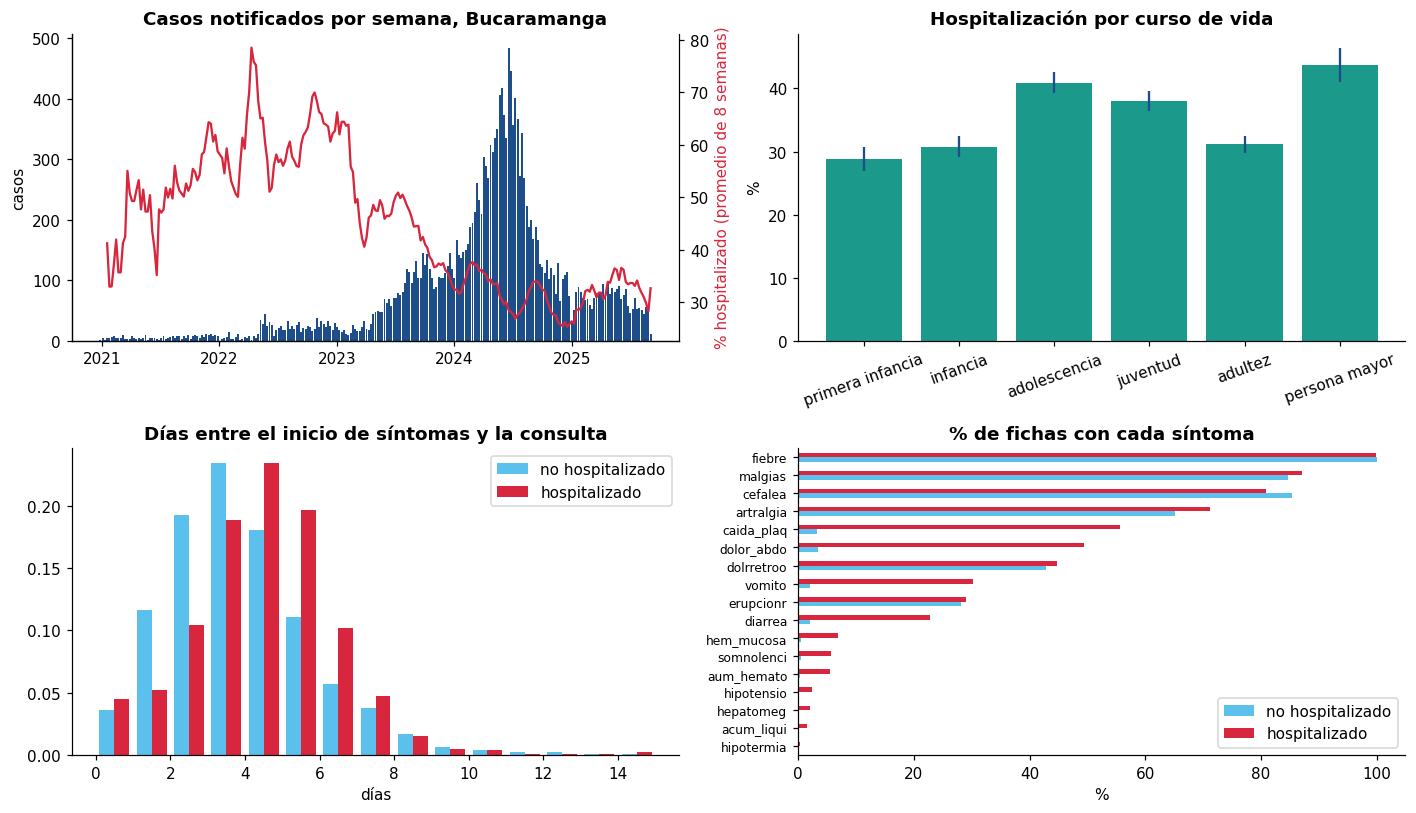

In [19]:
nombres_edad = ["primera infancia", "infancia", "adolescencia", "juventud", "adultez", "persona mayor"]
semana = limpio["fecha"].dt.to_period("W").dt.start_time
fig, ejes = plt.subplots(2, 2, figsize=(13, 7.5))

por_semana = y.groupby(semana).agg(["size", "mean"])
ejes[0, 0].bar(por_semana.index, por_semana["size"], width=6, color="#1D4E89")
ejes[0, 0].set(title=f"Casos notificados por semana, {CIUDAD.title()}", ylabel="casos")
otro = ejes[0, 0].twinx(); otro.plot(por_semana.index, por_semana["mean"].rolling(8, min_periods=4).mean() * 100, color="#D7263D")
otro.set_ylabel("% hospitalizado (promedio de 8 semanas)", color="#D7263D"); otro.spines["right"].set_visible(True)

por_edad = y.groupby(limpio["curso_de_vida"]).agg(["size", "mean"])
error = np.sqrt(por_edad["mean"] * (1 - por_edad["mean"]) / por_edad["size"])
ejes[0, 1].bar([nombres_edad[int(i)] for i in por_edad.index], por_edad["mean"] * 100, yerr=2 * error * 100, color="#1B998B", ecolor="#1D4E89")
ejes[0, 1].set(title="Hospitalización por curso de vida", ylabel="%"); ejes[0, 1].tick_params(axis="x", rotation=20)

dias = limpio["dias_hasta_consulta"].dropna()
ejes[1, 0].hist([dias[y == 0], dias[y == 1]], bins=range(0, 16), density=True, color=["#5BC0EB", "#D7263D"], label=["no hospitalizado", "hospitalizado"])
ejes[1, 0].set(title="Días entre el inicio de síntomas y la consulta", xlabel="días"); ejes[1, 0].legend()

frecuencia = limpio.groupby("hospitalizado")[SINTOMAS + ALARMA].mean().T * 100          # HUECO 7: la operación que convierte ceros y unos en una fracción
frecuencia.columns = ["no hospitalizado", "hospitalizado"]
frecuencia.sort_values("hospitalizado").plot.barh(ax=ejes[1, 1], color=["#5BC0EB", "#D7263D"])
ejes[1, 1].set(title="% de fichas con cada síntoma", xlabel="%"); ejes[1, 1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

**Una prueba de hipótesis: ¿los hospitalizados consultaron más tarde?** El histograma de abajo a la izquierda compara dos grupos. La prueba de Mann-Whitney contrasta

$$H_0:\ P(D_1>D_0)=\tfrac12\qquad\text{contra}\qquad H_1:\ P(D_1>D_0)\neq\tfrac12,$$

donde $D_1$ son los días hasta la consulta de un hospitalizado tomado al azar y $D_0$ los de un no hospitalizado. Usa rangos, así que no supone normalidad, que aquí no hay.

In [20]:
from scipy.stats import mannwhitneyu

dias_h, dias_n = dias[y.loc[dias.index] == 1], dias[y.loc[dias.index] == 0]
estadistico, valor_p = mannwhitneyu(dias_h, dias_n)
print(f"Mediana de días hasta la consulta | hospitalizados: {dias_h.median():.0f} | no hospitalizados: {dias_n.median():.0f}")
print(f"Media | hospitalizados: {dias_h.mean():.2f} | no hospitalizados: {dias_n.mean():.2f}")
print(f"P(D1 > D0) estimada: {estadistico / (len(dias_h) * len(dias_n)):.3f} | valor p: {valor_p:.2g}")

Mediana de días hasta la consulta | hospitalizados: 4 | no hospitalizados: 3
Media | hospitalizados: 4.01 | no hospitalizados: 3.45
P(D1 > D0) estimada: 0.601 | valor p: 1.5e-119


- Con miles de fichas, casi cualquier diferencia sale con un valor $p$ diminuto. Miren la probabilidad estimada: ¿qué tan lejos está de un medio? ¿La diferencia importa en la práctica? **Mi lectura:**

Respondan en una línea cada una.

- ¿El porcentaje de hospitalizados se mantiene estable en el tiempo, o cambia cuando llega la epidemia? **Mi lectura:**
- ¿Qué síntomas aparecen casi igual en los dos grupos y cuáles separan? Comparen con su segunda apuesta. **Mi lectura:**
- ¿Los hospitalizados consultaron antes o después que los demás? **Mi lectura:**

**¿Quiénes están en la tabla y quiénes no?** Una ficha existe solo si la persona consultó y el médico notificó. Quien pasó el dengue en la casa con acetaminofén no aparece. Respondan: ¿el porcentaje de hospitalizados de esta tabla sirve como estimación del riesgo de hospitalización de una persona con dengue? ¿Queda por encima o por debajo? **Mi respuesta:**

### 2.8 PCA: ¿los síntomas vienen en paquetes?

En clase usamos PCA para ver si las variables del hogar medían lo mismo. Aquí la pregunta es si los diecisiete síntomas se agrupan. Se estandariza la matriz de síntomas y se descompone su matriz de correlaciones:

$$R=V\Lambda V^\top,\qquad \text{varianza explicada por el componente } j=\frac{\lambda_j}{\sum_k\lambda_k}.$$

**Predicción escrita:** con diecisiete síntomas independientes, cada componente explicaría cerca de 6 %. ¿Cuánto explicará el primero? **Mi apuesta:**

In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(limpio[SINTOMAS + ALARMA])
pca = PCA().fit(Z)
explicada = pca.explained_variance_ratio_ * 100
cargas = pd.DataFrame(pca.components_.T[:, :3], index=SINTOMAS + ALARMA, columns=["CP1", "CP2", "CP3"])

resumen_pca(explicada, cargas, "Cargas: qué mezcla de síntomas es cada componente").show()
tipo = pd.Series(["síntomas generales"] * len(SINTOMAS) + ["signos de alarma"] * len(ALARMA), index=cargas.index)
nube_3d(cargas, grupo=tipo, colores={"síntomas generales": CIELO, "signos de alarma": ROJO}, etiquetas=True, tamano=7,
        titulo="Los diecisiete síntomas en tres componentes",
        subtitulo="Cada punto es un síntoma. Dos síntomas quedan cerca si aparecen en las mismas fichas. Arrastren para girar.",
        ejes=[f"CP{j + 1} ({explicada[j]:.0f} %)" for j in range(3)]).show()
print(f"Los tres primeros componentes explican {explicada[:3].sum():.0f} % de la varianza.")

Los tres primeros componentes explican 28 % de la varianza.


- ¿Los síntomas generales y los signos de alarma quedan en zonas distintas de la gráfica? **Mi lectura:**
- Si una ciudad marca fiebre en todas las fichas, esa columna no varía y su punto queda en el origen. ¿Qué le aporta al modelo una columna así? **Mi respuesta:**

## 3. Modelado

### 3.1 La partición y la trampa de la exactitud

En el ICFES partimos por colegio. Aquí lo que manda es el tiempo, como en la clase 1: el equipo siempre va a usar el modelo con casos posteriores a los que sirvieron para entrenarlo. Las fichas ya están ordenadas por fecha de notificación, y se cortan así:

$$\underbrace{\text{primer } 60\,\%}_{\text{entrenamiento}}\ \Big|\ \underbrace{20\,\%\ \text{siguiente}}_{\text{validación: se escoge}}\ \Big|\ \underbrace{\text{último } 20\,\%}_{\text{prueba: se reporta}}$$

Las tres medidas de la clase, con verdaderos y falsos positivos y negativos:

$$\text{exactitud}=\frac{VP+VN}{n},\qquad \text{sensibilidad}=\frac{VP}{VP+FN},\qquad \text{precisión}=\frac{VP}{VP+FP}.$$

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

variables = ["mujer", "curso_de_vida", "estrato", "subsidiado", "dias_hasta_consulta"] + SINTOMAS + ALARMA
X = limpio[variables]

n = len(limpio)
posicion = np.arange(n)
corte_1, corte_2 = int(0.6 * n), int(0.80 * n)              # HUECO 8: la fracción de fichas que va a entrenamiento
E, V, P = posicion < corte_1, (posicion >= corte_1) & (posicion < corte_2), posicion >= corte_2
for nombre, tramo in [("Entrenamiento", E), ("Validación", V), ("Prueba", P)]:
    print(f"{nombre:14s} {tramo.sum():5d} fichas | {limpio['fecha'][tramo].min().date()} a {limpio['fecha'][tramo].max().date()} | {y[tramo].mean() * 100:.1f} % hospitalizado")

Entrenamiento  11335 fichas | 2021-01-02 a 2024-06-22 | 37.8 % hospitalizado
Validación      3779 fichas | 2024-06-22 a 2024-09-30 | 31.0 % hospitalizado
Prueba          3779 fichas | 2024-09-30 a 2025-09-02 | 30.3 % hospitalizado


In [24]:
logistica = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(X[E], y[E])
dice_hospital = logistica.predict_proba(X[V])[:, 1] >= 0.5
real = y[V].values

def tres_medidas(real, dice):
    vp, fp, fn = ((dice == 1) & (real == 1)).sum(), ((dice == 1) & (real == 0)).sum(), ((dice == 0) & (real == 1)).sum()
    return {"exactitud": (dice == real).mean(), "sensibilidad": vp / (vp + fn), "precisión": vp / (vp + fp) if vp + fp else np.nan}   # HUECO 9: los hospitalizados que el modelo dejó pasar

display(pd.DataFrame({"decir que nadie se hospitaliza": tres_medidas(real, np.zeros(len(real))),
                      "regresión logística, umbral 0,5": tres_medidas(real, dice_hospital)}).T.round(3))

,exactitud,sensibilidad,precisión
decir que nadie se hospitaliza,0.690,0.000,NaN
"regresión logística, umbral 0,5",0.929,0.863,0.903


En el ICFES, decir que nadie quedaba abajo tenía casi la misma exactitud que el modelo. Miren si aquí pasa lo mismo y respondan: ¿por qué la exactitud engaña menos, o más, en este dato? Piensen en qué fracción de los casos es positiva y en qué tan fuerte es la señal de los síntomas. **Mi respuesta:**

Aun así, el equipo no decide con un umbral de 0,5. Decide con un número de llamadas. Por eso la métrica sigue siendo la captación, acompañada del área bajo la curva ROC, $\text{AUC}=P(\hat p_i>\hat p_j\mid y_i=1,\ y_j=0)$.

### 3.2 La línea base

Dos reglas sin modelo. La primera reparte las llamadas por sorteo. La segunda es el protocolo: llamar primero a quien tenga más signos de alarma. Esta segunda línea base es exigente, porque resume lo que la medicina ya sabe.

In [25]:
def captacion(real, puntaje, cupo=CUPO):
    """Fracción de los hospitalizados que cae entre los primeros `cupo` del orden. Los empates se rompen por sorteo."""
    real, puntaje = np.asarray(real), np.asarray(puntaje, dtype=float)
    k = int(round(cupo * len(real)))
    orden = np.lexsort((np.random.default_rng(0).random(len(real)), -puntaje))
    return float(real[orden[:k]].sum() / real.sum())          # HUECO 10: el denominador de la captación: todos los hospitalizados

reglas = {
    "sorteo": pd.Series(np.random.default_rng(1).random(n)),
    "regla: signos de alarma": limpio["signos_de_alarma"],
}
errores = {nombre: {"captación en validación": captacion(y[V], regla[V]), "captación en prueba": captacion(y[P], regla[P]),
                    "AUC en prueba": roc_auc_score(y[P], regla[P])} for nombre, regla in reglas.items()}
display(pd.DataFrame(errores).T.round(3))
print(f"Techo de la captación en prueba: {min(1, CUPO / y[P].mean()):.2f}")

,captación en validación,captación en prueba,AUC en prueba
sorteo,0.308,0.289,0.491
regla: signos de alarma,0.865,0.852,0.927


Techo de la captación en prueba: 0.99


Recuerden el techo de la clase: $\text{captación máxima}=\min(1,\ \text{cupo}/\hat p)$. Si se hospitalizan más casos de los que el equipo alcanza a llamar, ni un oráculo los cubre a todos.

### 3.3 Cinco modelos y el mismo protocolo de la clase

Los cinco candidatos son los de la clase: regresión logística, $\log\dfrac{p_i}{1-p_i}=\beta_0+x_i^\top\beta$; $k$ vecinos; árbol de decisión; bosque aleatorio y *gradient boosting*. Gana quien tenga mayor captación en **validación** y se reporta su captación en **prueba**.

**Predicción escrita:** ¿algún modelo le ganará a la regla de los signos de alarma en la prueba? ¿Por cuánto? **Mi apuesta:**

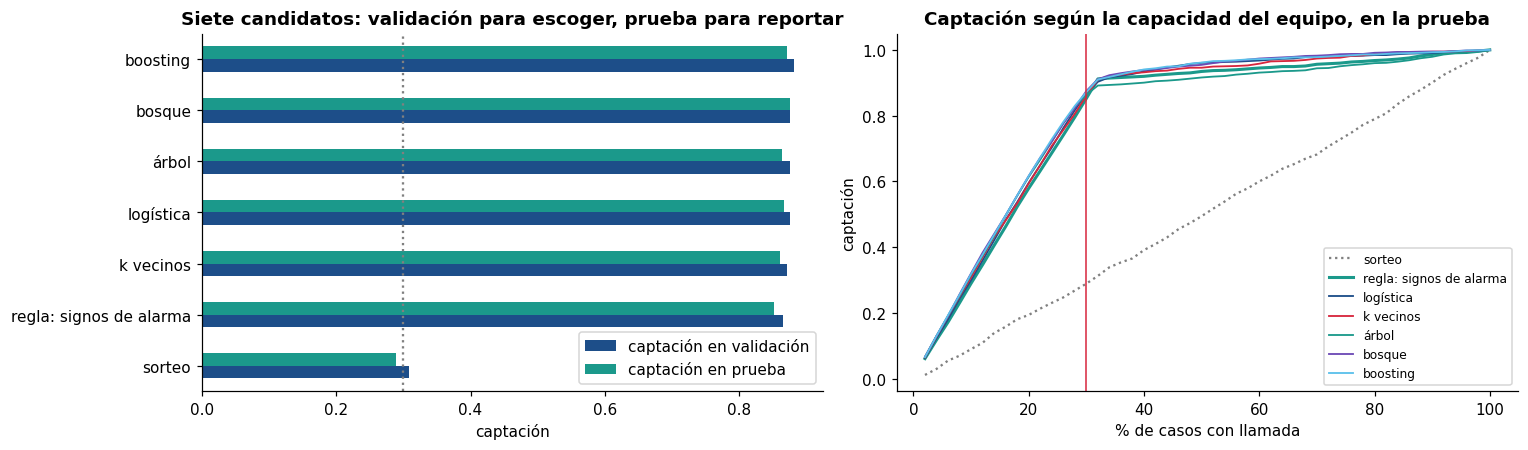

,captación en validación,captación en prueba,AUC en prueba
boosting,0.881,0.872,0.954
árbol,0.875,0.864,0.926
logística,0.875,0.867,0.945
bosque,0.875,0.875,0.955
k vecinos,0.872,0.861,0.943
regla: signos de alarma,0.865,0.852,0.927
sorteo,0.308,0.289,0.491


In [26]:
def cinco_modelos():
    llenar = lambda: SimpleImputer(strategy="median")
    return {
        "logística": make_pipeline(llenar(), StandardScaler(), LogisticRegression(max_iter=1000)),
        "k vecinos": make_pipeline(llenar(), StandardScaler(), KNeighborsClassifier(n_neighbors=50)),
        "árbol": make_pipeline(llenar(), DecisionTreeClassifier(max_depth=5, random_state=0)),
        "bosque": make_pipeline(llenar(), RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1)),
        "boosting": make_pipeline(llenar(), HistGradientBoostingClassifier(random_state=0)),
    }

puntajes = {nombre: regla[P] for nombre, regla in reglas.items()}
for nombre, modelo in cinco_modelos().items():
    modelo.fit(X[E], y[E])                                                # se entrena solo con el pasado
    en_validacion = captacion(y[V], modelo.predict_proba(X[V])[:, 1])
    modelo.fit(X[E | V], y[E | V])                                        # se reentrena con todo lo anterior a la prueba
    puntajes[nombre] = pd.Series(modelo.predict_proba(X[P])[:, 1], index=X.index[P])
    errores[nombre] = {"captación en validación": en_validacion, "captación en prueba": captacion(y[P], puntajes[nombre]),
                       "AUC en prueba": roc_auc_score(y[P], puntajes[nombre])}
todos = pd.DataFrame(errores).T

fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 4.2))
todos[["captación en validación", "captación en prueba"]].sort_values("captación en validación").plot.barh(ax=izq, color=["#1D4E89", "#1B998B"])
izq.axvline(CUPO, color="gray", ls=":"); izq.set(xlabel="captación", title="Siete candidatos: validación para escoger, prueba para reportar")
fracciones = np.linspace(0.02, 1, 50)
for nombre, puntaje in puntajes.items():
    estilo = {"color": "gray", "ls": ":"} if nombre == "sorteo" else {"color": "#1B998B", "lw": 2} if nombre.startswith("regla") else {"lw": 1.2}
    der.plot(fracciones * 100, [captacion(y[P], puntaje, f) for f in fracciones], label=nombre, **estilo)
der.axvline(CUPO * 100, color="#D7263D", lw=1)
der.set(xlabel="% de casos con llamada", ylabel="captación", title="Captación según la capacidad del equipo, en la prueba"); der.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(todos.sort_values("captación en validación", ascending=False).round(3))

**¿Por qué el ganador se escoge en validación y no en prueba?** Respondan en dos líneas, con sus palabras: **Mi respuesta:**

In [27]:
mejor = todos.drop(index="sorteo")["captación en validación"].idxmax()        # HUECO 11: la columna con la que se escoge al ganador
resumen = todos["captación en prueba"].round(3)
regla = "regla: signos de alarma"
print(f"Ganador en validación: {mejor}")
print(f"Captación en prueba: {resumen[mejor]:.3f} | regla de los signos de alarma: {resumen[regla]:.3f} | sorteo: {resumen['sorteo']:.3f} | techo: {min(1, CUPO / y[P].mean()):.2f}")

Ganador en validación: boosting
Captación en prueba: 0.872 | regla de los signos de alarma: 0.852 | sorteo: 0.289 | techo: 0.99


Comparen con su tercera apuesta. La distancia entre el ganador y la regla es lo que el modelo agrega a lo que el protocolo ya sabía. Escriban en una línea si esa distancia justifica cambiar la regla por un modelo: **Mi lectura:**

**Por qué quedan tan cerca.** La respuesta que modelamos es una decisión del médico, y la guía de atención le indica hospitalizar a quien tiene signos de alarma. El modelo aprende, en buena parte, la regla que produjo el dato. Dos preguntas para cerrar:

- Si el modelo imita al protocolo, ¿puede este cuaderno decir si el protocolo se equivoca? **Mi respuesta:**
- ¿Qué habría que medir para saberlo, y está ese dato en la ficha? **Mi respuesta:**

### 3.4 La trampa de la clase: columnas que filtran la respuesta

En la sección 2.6 guardé dos columnas sin dárselas al modelo. `conducta` dice qué se hizo con el paciente, y uno de sus valores es «hospitalización en piso». `clasfinal` es la clasificación con que se cerró el caso. Las dos se llenan cuando ya se sabe en qué terminó el paciente.

**Predicción escrita:** ¿a cuánto llegará el AUC si el modelo recibe `conducta`? **Mi apuesta:**

In [28]:
escenarios = {
    "solo paciente y síntomas": [],
    "+ clasfinal": ["clasfinal"],
    "+ conducta": ["conducta"],                         # HUECO 12: la columna que dice qué se hizo con el paciente, entre comillas
    "+ las dos": ["clasfinal", "conducta"],
}
fuga = {}
for nombre, columnas in escenarios.items():
    X_con = limpio[variables + columnas]
    modelo = cinco_modelos()["boosting"].fit(X_con[E | V], y[E | V])
    prob = modelo.predict_proba(X_con[P])[:, 1]
    fuga[nombre] = {"captación en prueba": captacion(y[P], prob), "AUC en prueba": roc_auc_score(y[P], prob),
                    "exactitud con umbral 0,5": ((prob >= 0.5) == y[P]).mean()}
display(pd.DataFrame(fuga).T.round(3))

,captación en prueba,AUC en prueba,"exactitud con umbral 0,5"
solo paciente y síntomas,0.872,0.954,0.928
+ clasfinal,0.873,0.955,0.931
+ conducta,0.958,0.990,0.978
+ las dos,0.956,0.990,0.978


- ¿Cuál de las cuatro filas es el resultado que se le puede prometer al equipo? **Mi respuesta:**
- La pregunta que detecta la fuga es: el día en que se toma la decisión, ¿esta columna ya existe? Aplíquenla a `caida_plaq` (caída de plaquetas) y a `aum_hemato` (aumento del hematocrito), que salen de un examen de laboratorio. ¿El equipo las tiene cuando decide a quién llamar? **Mi respuesta:**

### 3.5 Explicar: ¿qué acompaña a la hospitalización?

Como en clase, $e^{\beta_j}$ es la razón de probabilidades asociada a subir una desviación estándar en la variable $j$, con las demás quietas:

$$\text{OR}_j=e^{\beta_j}.$$

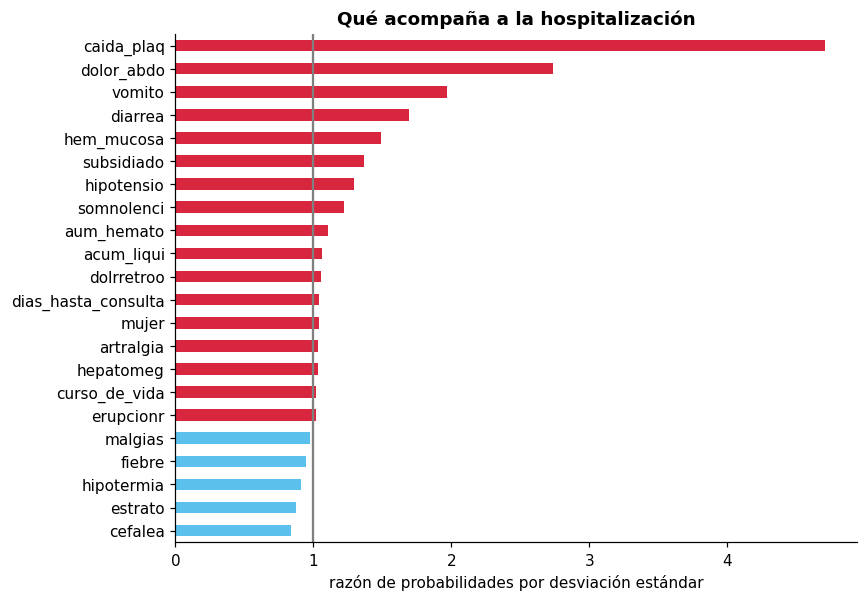

cefalea                0.84
estrato                0.88
hipotermia             0.91
fiebre                 0.95
malgias                0.97
erupcionr              1.02
curso_de_vida          1.02
hepatomeg              1.03
artralgia              1.04
mujer                  1.04
dias_hasta_consulta    1.04
dolrretroo             1.06
acum_liqui             1.06
aum_hemato             1.11
somnolenci             1.22
hipotensio             1.30
subsidiado             1.37
hem_mucosa             1.49
diarrea                1.69
vomito                 1.97
dolor_abdo             2.74
caida_plaq             4.71


In [29]:
logistica = cinco_modelos()["logística"].fit(X[E | V], y[E | V])
razones = pd.Series(np.exp(logistica[-1].coef_[0]), index=variables).sort_values()
razones.plot.barh(figsize=(8, 6), color=["#5BC0EB" if r < 1 else "#D7263D" for r in razones])
plt.axvline(1, color="gray"); plt.xlabel("razón de probabilidades por desviación estándar")
plt.title("Qué acompaña a la hospitalización"); plt.show()
print(razones.round(2).to_string())

- ¿Qué tres variables pesan más? ¿Son signos de alarma? **Mi lectura:**
- Estos números describen asociaciones. Un signo de alarma puede aparecer en la ficha porque el paciente ya estaba hospitalizado y le hicieron exámenes. ¿Cómo cambia eso la lectura de la gráfica? **Mi respuesta:**

### 3.6 Sesgos: ¿a quién le acierta y a quién le falla el modelo?

La misma auditoría de la clase. Para cada grupo: qué fracción se hospitalizó, qué fracción recibe llamada, la captación dentro del grupo y las **llamadas de sobra**, que son los casos que no se hospitalizaron y recibieron llamada.

In [30]:
elegido = mejor if resumen[mejor] > resumen[regla] else regla            # el más simple entre los que no pierden
puntaje = puntajes[elegido]
k = int(round(CUPO * P.sum()))
orden = np.lexsort((np.random.default_rng(0).random(P.sum()), -puntaje.values))
llamada = pd.Series(False, index=X.index[P]); llamada.iloc[orden[:k]] = True

def auditar(grupo):
    partes = {}
    for valor, indices in grupo[P].groupby(grupo[P]).groups.items():
        yy, cc = y[indices], llamada[indices]
        partes[valor] = {"n": len(yy), "% hospitalizado": yy.mean() * 100, "% con llamada": cc.mean() * 100,
                         "captación": cc[yy == 1].mean(), "llamadas de sobra": cc[yy == 0].mean()}
    return pd.DataFrame(partes).T

grupos = {
    "sexo": limpio["mujer"].map({1.0: "mujeres", 0.0: "hombres"}),
    "régimen": limpio["subsidiado"].map({1.0: "subsidiado", 0.0: "otros regímenes"}),
    "edad": (limpio["curso_de_vida"] <= 2).map({True: "menores de 18", False: "adultos"}),
}
auditoria = pd.concat({nombre: auditar(grupo) for nombre, grupo in grupos.items()})
print("Candidato auditado:", elegido)
display(auditoria.round({"n": 0, "% hospitalizado": 1, "% con llamada": 1, "captación": 2, "llamadas de sobra": 2}))

Candidato auditado: boosting


n  % hospitalizado  % con llamada  captación  \
sexo    hombres          1978.0             28.9           28.1       0.85   
        mujeres          1801.0             31.9           32.1       0.89   
régimen otros regímenes  2976.0             24.5           25.2       0.86   
        subsidiado        803.0             51.8           47.9       0.90   
edad    adultos          2066.0             33.4           32.7       0.86   
        menores de 18    1713.0             26.6           26.8       0.89   

                         llamadas de sobra  
sexo    hombres                       0.05  
        mujeres                       0.05  
régimen otros regímenes               0.06  
        subsidiado                    0.03  
edad    adultos                       0.06  
        menores de 18                 0.04

- ¿En qué grupo es más baja la captación? Esos son los hospitalizados que la regla deja sin llamada. **Mi lectura:**
- El régimen subsidiado cubre a la población con menos recursos. ¿El modelo los atiende igual que a los demás? **Mi lectura:**

## 4. Comunicación

### 4.1 Decidir: ¿a quiénes llama el equipo?

Para ponerle margen a la captación usamos *bootstrap* por semana: se sacan muchas veces, con reposición, las semanas de la prueba y se recalcula la captación. El intervalo de 90 % va del percentil 5 al 95,

$$\bigl[\hat Q_{0{,}05}(\text{captación}^*),\ \hat Q_{0{,}95}(\text{captación}^*)\bigr].$$

Se remuestrean semanas completas porque los casos de una misma semana comparten la misma etapa de la epidemia.

In [33]:
semana_prueba = limpio["fecha"][P].dt.to_period("W").astype(str).values
semanas = np.unique(semana_prueba)
filas_por_semana = {s: np.flatnonzero(semana_prueba == s) for s in semanas}
sorteo = np.random.default_rng(0)
replicas = {"elegido": [], "regla": []}
for _ in range(500):
    filas = np.concatenate([filas_por_semana[s] for s in sorteo.choice(semanas, len(semanas))])
    replicas["elegido"].append(captacion(y[P].values[filas], puntajes[elegido].values[filas]))
    replicas["regla"].append(captacion(y[P].values[filas], puntajes[regla].values[filas]))
bajo_, alto_ = np.percentile(replicas["elegido"], [90, 95])              # HUECO 13: el percentil inferior de un intervalo de 90 %
ventaja = np.array(replicas["elegido"]) - np.array(replicas["regla"])

precision = y[P][llamada].mean()
print(f"Ciudad: {CIUDAD} | Candidato elegido: {elegido}")
print(f"Captación en prueba: {resumen[elegido]:.2f}, con intervalo de 90 % entre {bajo_:.2f} y {alto_:.2f}")
print(f"Ventaja sobre la regla de los signos de alarma: {np.median(ventaja):+.2f} (intervalo de 90 %: {np.percentile(ventaja, 5):+.2f} a {np.percentile(ventaja, 95):+.2f})")
print(f"De cada 100 llamadas, {precision * 100:.0f} van a pacientes que terminaron hospitalizados. Por sorteo irían {y[P].mean() * 100:.0f}.")
print(f"De cada 100 hospitalizados, {(1 - resumen[elegido]) * 100:.0f} se quedan sin llamada.")

Ciudad: bucaramanga | Candidato elegido: boosting
Captación en prueba: 0.87, con intervalo de 90 % entre 0.90 y 0.90
Ventaja sobre la regla de los signos de alarma: +0.01 (intervalo de 90 %: +0.01 a +0.02)
De cada 100 llamadas, 88 van a pacientes que terminaron hospitalizados. Por sorteo irían 30.
De cada 100 hospitalizados, 13 se quedan sin llamada.


### La decisión en tres frases

Para la secretaria de salud, que es médica y no sabe qué es un *bootstrap*.

1. **Recomendación:**
2. **Evidencia:**
3. **Riesgo:**

### 4.2 Bitácora de decisiones

Llenen las filas vacías. La primera va de ejemplo.

| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Todo `-89` es un faltante | Dejarlo como número | No es un valor de la variable: es la marca de una celda vacía |
| Fechas con dos formatos explícitos | | |
| Solo fichas desde 2021 | | |
| Diccionario de `conducta` y `clasfinal` deducido del dato | | |
| Fuera las fichas con `ajuste_` 6 y con `cod_eve` 580 | | |
| Faltantes llenos con la mediana de entrenamiento | | |
| Partición por tiempo | | |
| `conducta` y `clasfinal` fuera del modelo | | |
| Captación con cupo de 30 % como métrica | | |

### 4.3 Riesgos, ética y mantenimiento

Este dato es de pacientes. Viene sin nombres, pero trae edad, sexo, régimen, estrato, grupo poblacional y fechas.

- La ficha no dice si los síntomas se anotaron antes o después de hospitalizar al paciente. ¿Qué le pasa al modelo si se anotaron después?
- El diccionario de códigos es una deducción. ¿Qué parte de sus resultados cambiaría si el código 4 de `conducta` no fuera «observación»?
- En un municipio pequeño, ¿se podría reconocer a una persona cruzando edad, sexo, fecha y grupo poblacional? ¿Qué columnas quitarían antes de publicar una tabla así?
- El modelo se entrenó en una epidemia. ¿Cada cuánto habría que revisarlo, y qué señal les diría que dejó de servir?
- Una llamada de seguimiento no le hace daño a nadie. ¿Qué cambiaría si el mismo modelo se usara para decidir a quién no se hospitaliza?

### 4.4 Procedencia

In [32]:
procedencia()["dengue"]

{'titulo': 'Dengue: casos notificados al SIVIGILA en Bucaramanga o en Tuluá',
 'fuente': 'Alcaldías de Bucaramanga y de Tuluá, en datos.gov.co, conjuntos qzc7-jbg3 y dq2k-gub9',
 'origen': 'fuente oficial',
 'descargado': '2026-11-25 01:19 UTC',
 'filas': 28626,
 'md5': '8f62e2cb45d86536c50cc893a8c0c00d',
 'variante': 'dengue_ciudad-bucaramanga'}

### 4.5 Cambien una línea

Vuelvan a la celda donde dice `CIUDAD = "bucaramanga"`, pongan `CIUDAD = "tulua"` y corran todo de nuevo con *Entorno de ejecución*, *Ejecutar todo*. Ninguna otra línea cambia: las funciones de limpieza sirven para las dos ciudades. Llenen la tabla con sus dos corridas.

| | Bucaramanga | Tuluá |
|---|---|---|
| Fichas descargadas y fichas que quedan | | |
| Fichas descartadas (`ajuste_` 6) | | |
| % hospitalizado | | |
| Techo de la captación | | |
| Ganador en validación | | |
| Captación del ganador en prueba | | |
| Captación de la regla de los signos de alarma | | |
| AUC honesto y AUC con `conducta` | | |

Con la tabla llena, respondan en tres líneas. ¿Qué trampa de limpieza pesó más en cada ciudad? ¿El modelo de una ciudad serviría en la otra, y qué habría que comprobar antes de intentarlo? **Mi respuesta:**

Dejen el cuaderno entregado con `CIUDAD = "tulua"` corrido y la tabla completa.

**Para entregar:** en Colab, menú *Archivo*, *Guardar una copia en GitHub*, y escojan su repositorio de portafolio, carpeta `clase02/`. Un cuaderno que no corre de principio a fin desde cero no se califica: antes de guardar usen *Entorno de ejecución*, *Reiniciar sesión y ejecutar todo*.